![Python Banner](../../Image/05_01_tree_based_models.png)


# 1.2 Causal Forest (CF) for Heterogeneous Treatment Effect Estimation


## Overview

A **Causal Forest** is a machine learning method within the Generalized Random Forests framework, designed to estimate **Heterogeneous Treatment Effects (HTE)** — specifically the **Conditional Average Treatment Effect (CATE)** — across individuals in observational or experimental studies.

It adapts the classic random forest algorithm for causal inference, asking not *"what will happen?"* but *"what is the effect of treatment for this type of person?"*

### Key Concepts

**Treatment Effect** measures the difference in outcomes between a treated and untreated individual:

$$\tau(x) = E[Y(1) - Y(0) \mid X = x]$$

where $Y(1)$ is the outcome if treated, $Y(0)$ if untreated, $X$ represents covariates (age, sex, income, etc.), and $\tau(x)$ is the CATE — the expected treatment effect for an individual with covariates $X = x$.

**Heterogeneity** is the core motivation: treatment effects aren't uniform. A drug may work better for older patients; an intervention may help high-income households more than low-income ones. Causal forests find *where* and *how much* these effects vary.

**Random Forest Foundation:** Like standard random forests, causal forests use an ensemble of decision trees — but trees are grown to maximize heterogeneity in treatment effects, not prediction accuracy.

### How It Works: Five Steps

**1. Data Requirements** — You need three things: an outcome $Y$ (e.g. survival time, test score), a treatment indicator $W$ (binary or continuous: treated vs. control), and covariates $X$ (features like age, income).

**2. Tree Construction** — Each tree is grown on a random data/feature subset. Splits are chosen to maximally separate groups with *different* treatment effects — not to minimize prediction error. The criterion targets variance in $\tau(x)$ across branches.

**3. Honest Estimation** — To avoid overfitting, one subsample determines the *tree structure* (splits), and a held-out subsample *estimates treatment effects* within each leaf. This ensures unbiased $\tau(x)$ estimates.

**4. Aggregation** — All trees are averaged into a smooth, non-parametric estimate of $\tau(x)$ across the covariate space.

**5. Outputs** — The forest produces: CATE estimates $\tau(x)$ per individual, an Average Treatment Effect (ATE) $= E[\tau(X)]$, and variable importance scores showing which covariates drive treatment effect heterogeneity.


![Causal forest](../../Image/causal_forest.png)


The diagram walks through all five stages end-to-end:

- **Inputs** (teal/purple/coral) flow into tree construction, where the key innovation is the split criterion — rather than minimizing prediction error, each split maximizes the *difference in treatment effects* $\Delta\tau(x)$ between branches.
- **Honest estimation** (blue/amber) prevents overfitting by separating the data used to grow the tree structure from the data used to estimate effects in the leaves.
- **Aggregation** smooths across all $B$ trees, producing a robust, non-parametric CATE surface.
- **Outputs** give you per-individual CATE estimates, a population-level ATE, and variable importance — telling you *which* characteristics matter most for treatment response.


## Causal Forest (CF) in Python

This tutorial uses `CausalForest` from PyCausalML. We'll cover:

- Getting started with a causal forest on simulated data
- A use case fit on the abortion repeal dataset from `causaldata`

Each section includes:

- Data preparation
- Model fitting with `CausalForest`
- Estimation of the average treatment effect and individual CATEs
- Visualization of treatment-effect heterogeneity, variable importance, and SHAP values
- Interpretation of results


## Setup

This notebook fits **`CausalForest`** from **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml.tree_based_models`).

`fit(X, treatment, y)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `average_treatment_effect`, `rank_average_treatment_effect`, `feature_importance`, `explain`, and `plot_shap`.

Install the package from this repository, with the plotting extras. The abortion use case is loaded with `causaldata`.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]", "statsmodels", "causaldata",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from pycausalml import (
    CausalForest,
    synthetic_data,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


## Getting started with simulated data

Before applying a causal forest to real data, it helps to use simulated data where the true treatment effects are known. This checks that the forest recovers the underlying heterogeneity.

### Data generation

Generate data with `synthetic_data()`: a nonlinear baseline, heterogeneous treatment effects, and a propensity that depends on covariates.


In [3]:
dat_sim = synthetic_data(mode=2, n=3000, p=20, sigma=5.5, random_state=42)
y_sim = dat_sim["y"]
X_sim = dat_sim["X"]
w_sim = dat_sim["w"]
tau_sim = dat_sim["tau"]
feature_names_sim = [f"X{i}" for i in range(1, X_sim.shape[1] + 1)]
print(X_sim.shape, y_sim.shape, "true CATE mean", round(float(tau_sim.mean()), 3))


(3000, 20) (3000,) true CATE mean 0.503


Create a data frame with the outcome, treatment, and true CATE:


In [4]:
df_sim = pd.DataFrame(X_sim, columns=feature_names_sim)
df_sim["outcome"] = y_sim
df_sim["treatment"] = w_sim
df_sim["tau_true"] = tau_sim
print(f"Simulated data: {len(df_sim)} rows, {X_sim.shape[1]} covariates")
print(df_sim["tau_true"].describe())
print(df_sim["treatment"].value_counts())


Simulated data: 3000 rows, 20 covariates
count    3000.000000
mean        0.502812
std         0.868168
min        -2.418788
25%         0.000000
50%         0.000000
75%         1.034384
max         4.348603
Name: tau_true, dtype: float64
treatment
1    1518
0    1482
Name: count, dtype: int64


### Train-test split

Split into training (80%) and test (20%) so CATE estimates can be compared with the known effects.


In [5]:
rng = np.random.default_rng(42)
train_prop = 0.8
n_sim = len(df_sim)
train_idx_sim = rng.choice(n_sim, size=round(train_prop * n_sim), replace=False)
test_idx_sim = np.setdiff1d(np.arange(n_sim), train_idx_sim)
df_train_sim = df_sim.iloc[train_idx_sim].reset_index(drop=True)
df_test_sim = df_sim.iloc[test_idx_sim].reset_index(drop=True)
print("Train:", len(df_train_sim), "| Test:", len(df_test_sim))


Train: 2400 | Test: 600


### Fitting a causal forest on training data

Fit a causal forest on the simulated training data. Honest cross-fitting builds the nuisance models, and the forest averages many trees. Increase `num_trees` for a more stable fit.


In [6]:
covar_names_sim = [c for c in df_train_sim.columns if c not in {"outcome", "treatment", "tau_true"}]
cf_sim = CausalForest(
    num_trees=80, min_node_size=5, sample_fraction=0.5, random_state=123,
)
cf_sim.fit(
    df_train_sim[covar_names_sim].to_numpy(),
    df_train_sim["treatment"].to_numpy(),
    df_train_sim["outcome"].to_numpy(),
    feature_names=covar_names_sim,
)
print("Trees:", cf_sim.num_trees, "| features:", len(cf_sim.feature_names_))


Trees: 80 | features: 20


### ATE estimation on training data

The ATE is the average treatment effect across the training population, with a 95% confidence interval. On simulated data we can compare it with the mean of the true CATE.


In [7]:
ate_sim = cf_sim.average_treatment_effect()
print(f"Training ATE: {ate_sim['estimate']:.4f} ± {1.96 * ate_sim['std.err']:.4f} (95% CI)")
print("True training ATE:", round(float(df_train_sim["tau_true"].mean()), 4))


Training ATE: 0.0672 ± 0.4561 (95% CI)
True training ATE: 0.4997


### Estimating treatment effects on test data

Predict CATE for the test set and compare it with the true treatment effect.


Test set CATE summary:
  Predicted CATE: mean = 0.0784, sd = 1.5618
  True CATE:      mean = 0.5151, sd = 0.8785
  Correlation (pred vs true): 0.3557


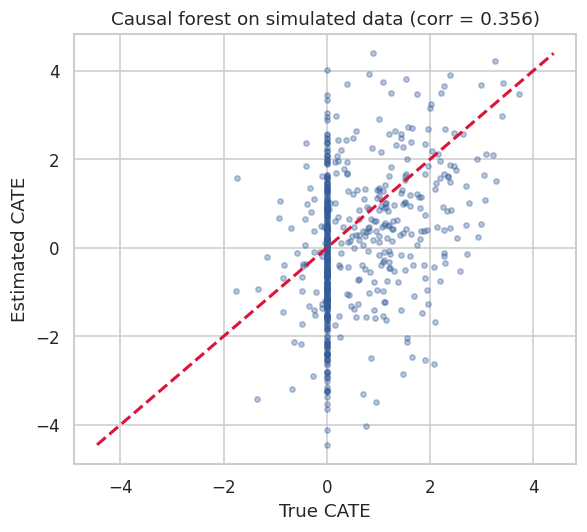

In [8]:
cate_sim_pred = cf_sim.predict(df_test_sim[covar_names_sim].to_numpy())
tau_te = df_test_sim["tau_true"].to_numpy()
cor_te = np.corrcoef(cate_sim_pred, tau_te)[0, 1]
print("Test set CATE summary:")
print(f"  Predicted CATE: mean = {cate_sim_pred.mean():.4f}, sd = {cate_sim_pred.std():.4f}")
print(f"  True CATE:      mean = {tau_te.mean():.4f}, sd = {tau_te.std():.4f}")
print("  Correlation (pred vs true):", round(float(cor_te), 4))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(tau_te, cate_sim_pred, s=12, alpha=0.35, c="#335C99")
lims = [min(tau_te.min(), cate_sim_pred.min()), max(tau_te.max(), cate_sim_pred.max())]
ax.plot(lims, lims, ls="--", c="crimson", lw=2)
ax.set_xlabel("True CATE")
ax.set_ylabel("Estimated CATE")
ax.set_title(f"Causal forest on simulated data (corr = {cor_te:.3f})")
fig.tight_layout()
plt.show()


### Variable Importance

Variable importance shows which covariates the forest used most when splitting to capture heterogeneity in treatment effects.


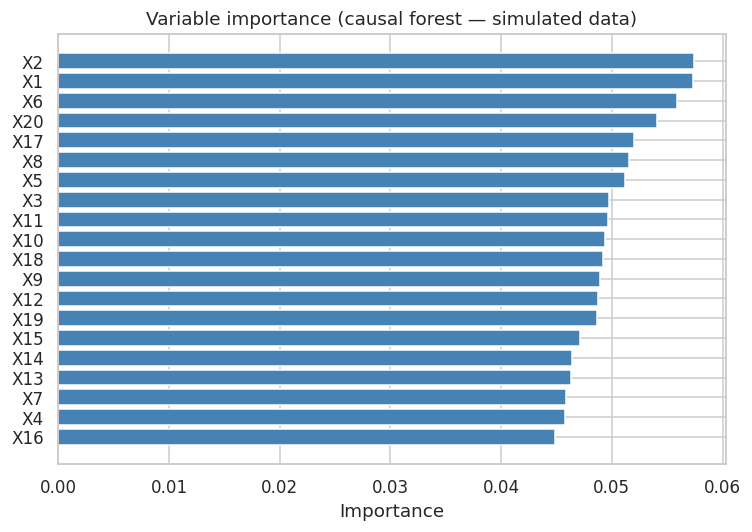

In [9]:
importance_df_sim = pd.DataFrame({
    "Feature": cf_sim.feature_names_,
    "Importance": cf_sim.feature_importance(),
}).sort_values("Importance")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance_df_sim["Feature"], importance_df_sim["Importance"], color="steelblue")
ax.set_title("Variable importance (causal forest — simulated data)")
ax.set_xlabel("Importance")
fig.tight_layout()
plt.show()


## Use Case

We use the **abortion** dataset from the `causaldata` package, which examines the effect of abortion legalization (early repeal) on gonorrhea incidence among 15–19 year olds as a proxy for risky sexual behavior. By the end of this section, you'll see how a causal forest estimates who was more affected by the policy, and how to read the average effect, the CATE distribution, and the covariates that drive heterogeneity.


### Data

The **abortion** dataset contains state-year observations on gonorrhea rates among 15–19 year olds, with a binary indicator for early repeal of abortion prohibition. It is commonly used to study the **causal effects of abortion legalization policies** on **risky sexual behavior** among teenagers. Risky behavior is proxied by the **incidence of gonorrhea** among 15–19 year olds.

Here are the most important columns:

- **fip** — State FIPS code (numeric identifier for each U.S. state)
- **age** — Age in years (focused on 15–19 year olds)
- **race** — Race: 1 = white, 2 = black (or similar coding)
- **year** — Calendar year
- **t** — A rescaled time variable (often centered around policy change)
- **sex** — Sex: 1 = male, 2 = female
- **totpop** — Total population (state-level)
- **ir** — Incarcerated males per 100,000 (proxy for criminal justice environment)
- **crack** — Crack cocaine index (proxy for drug epidemic intensity)
- **alcohol** — Alcohol consumption per capita
- **income** — Real income per capita
- **ur** — State unemployment rate
- **poverty** — Poverty rate
- **repeal** — Treatment indicator: 1 = state had an **early repeal** of abortion prohibition (treatment group), 0 = otherwise (control group)
- **acc** — Cumulative AIDS mortality per 100,000
- **wht** — White indicator
- **male** — Male indicator
- **younger** — Indicator for the younger age group
- **fa** — State-by-younger interaction (mostly missing; dropped below)
- **pi** — Parental involvement law in effect
- **bf15** — Indicator: black female in the 15–19 age group


### Load Data

The **outcome variable** is **lnr** (logged gonorrhea rate per 100,000 population among 15–19 year olds).


In [10]:
from causaldata import abortion

abortion_df = abortion.load_pandas().data.copy()
print("Abortion dataset loaded. Columns:", list(abortion_df.columns))
print(abortion.NOTE)
print(abortion.DESCRLONG)
print(abortion.SOURCE)


Abortion dataset loaded. Columns: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'repeal', 'acc', 'wht', 'male', 'lnr', 't', 'younger', 'fa', 'pi', 'bf15']
::
    Number of observations - 19584
    Number of variables - 22
    Variables name definitions::
            fip - State FIPS code
            age - Age in years
            race - Race: 1 = white, 2 = black
            year - Year
            t - Year but on a different scale
            sex - Sex: 1 = male, 2 = female
            totpop - Total population
            ir - Incarcerated Males per 100,000
            crack - Crack index
            alcohol - Alcohol consumption per capita
            income - Real income per capita
            ur - State unemployment rate
            poverty - Poverty rate
            repeal - In a state with an early repeal of abortion prohibition
            acc - AIDS mortality per 100,000 cumulative in t, t-1, t-2, t-3
            wht - Whi

### Data Visualization


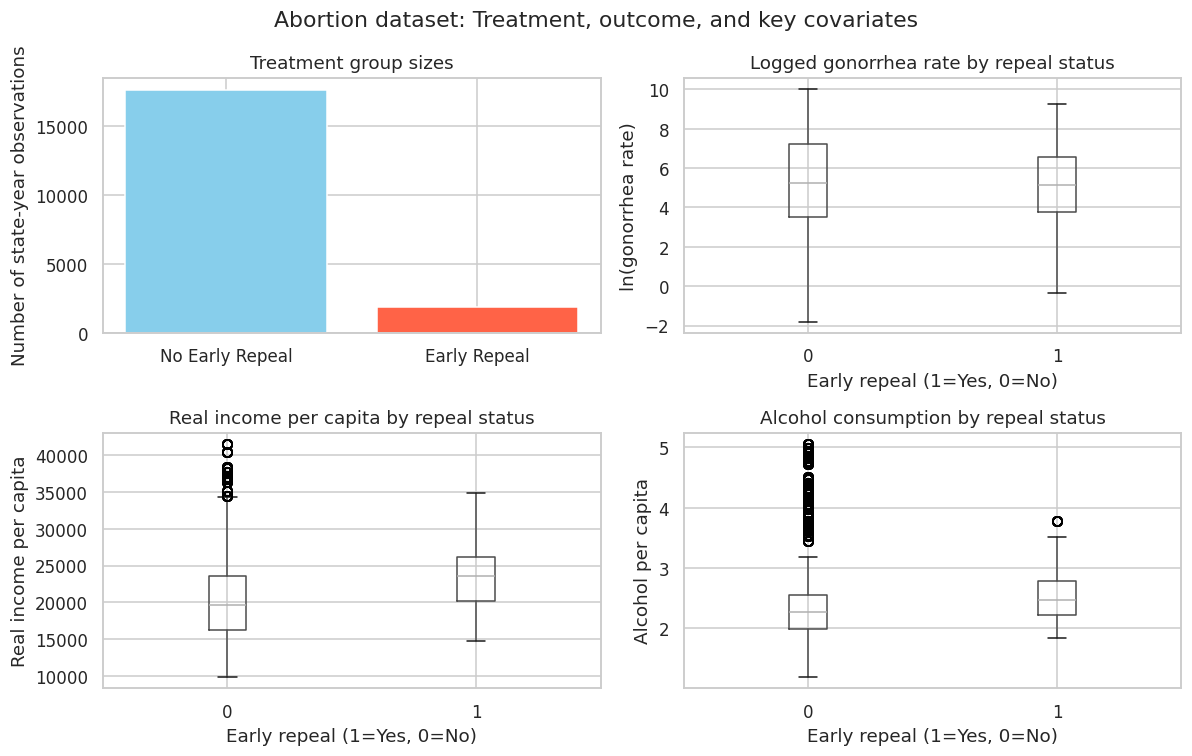

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

counts = abortion_df.loc[:, abortion_df.columns.str.lower() == "repeal"].squeeze().value_counts().sort_index()
axes[0, 0].bar(["No Early Repeal", "Early Repeal"], counts.to_numpy(), color=["skyblue", "tomato"])
axes[0, 0].set_title("Treatment group sizes")
axes[0, 0].set_ylabel("Number of state-year observations")

abortion_df.boxplot(column="lnr", by="repeal", ax=axes[0, 1])
axes[0, 1].set_title("Logged gonorrhea rate by repeal status")
axes[0, 1].set_xlabel("Early repeal (1=Yes, 0=No)")
axes[0, 1].set_ylabel("ln(gonorrhea rate)")

abortion_df.boxplot(column="income", by="repeal", ax=axes[1, 0])
axes[1, 0].set_title("Real income per capita by repeal status")
axes[1, 0].set_xlabel("Early repeal (1=Yes, 0=No)")
axes[1, 0].set_ylabel("Real income per capita")

abortion_df.boxplot(column="alcohol", by="repeal", ax=axes[1, 1])
axes[1, 1].set_title("Alcohol consumption by repeal status")
axes[1, 1].set_xlabel("Early repeal (1=Yes, 0=No)")
axes[1, 1].set_ylabel("Alcohol per capita")

plt.suptitle("Abortion dataset: Treatment, outcome, and key covariates")
fig.tight_layout()
plt.show()


### Data Processing for Causal Forest

Covariates are every column except the outcome (`lnr`) and the treatment (`repeal`). Columns with no usable variation are dropped. `fa` is almost entirely missing, so its variance is undefined and it is removed. Rows with a missing logged gonorrhea rate cannot be used for estimation, so those rows are dropped before the split.


In [12]:
feature_names = abortion_df.columns.drop(["lnr", "repeal"])
X = abortion_df[feature_names].to_numpy()
Y = abortion_df["lnr"].to_numpy(dtype=float)
W = abortion_df["repeal"].to_numpy()
keep = X.var(axis=0) > 1e-10
X = X[:, keep]
feature_names = [name for name, flag in zip(feature_names, keep) if flag]
complete = np.isfinite(Y)
X, Y, W = X[complete], Y[complete], W[complete]
print("Covariates used:", feature_names)
print("n =", len(Y), " treated =", int(W.sum()))
print("Dropped rows with missing lnr:", int((~complete).sum()))


Covariates used: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']
n = 17921  treated = 1854
Dropped rows with missing lnr: 1663


### Split Data into Training and Test Sets

80% training, 20% test.


In [13]:
rng_abortion = np.random.default_rng(42)
n = len(Y)
train_idx = rng_abortion.choice(n, size=round(0.8 * n), replace=False)
test_idx = np.setdiff1d(np.arange(n), train_idx)
X_train, X_test = X[train_idx], X[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]
W_train, W_test = W[train_idx], W[test_idx]
print("Training set size:", len(Y_train))
print("Test set size:", len(Y_test))
print("Column names of X_train:", feature_names)


Training set size: 14337
Test set size: 3584
Column names of X_train: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']


### Build Training Data Frame for Causal Forest


In [14]:
df = pd.DataFrame(X_train, columns=feature_names)
df["outcome"] = Y_train
df["treatment"] = W_train
print(df["treatment"].value_counts())
print(df["treatment"].value_counts(normalize=True).round(3))


treatment
0    12857
1     1480
Name: count, dtype: int64
treatment
0    0.897
1    0.103
Name: proportion, dtype: float64


### Fitting a Causal Forest

`CausalForest` estimates conditional average treatment effects with a doubly robust forest. Cross-fitted outcome and propensity models form an augmented inverse-propensity score, and a random forest regresses that score on the covariates.

Constructor arguments:

- `num_trees` (default 100): number of trees in the forest.
- `min_node_size` (default 5): minimum number of observations in each leaf.
- `sample_fraction` (default 0.5): fraction of rows used to build each tree.
- `n_splits` (default 2): number of folds for the cross-fitted nuisance models.
- `nuisance` (default `"gbr"`): regressor used for the outcome models.
- `nuisance_estimators` (default 40): number of trees or boosting stages in each nuisance model.
- `random_state`: seed for cross-fitting and the forest.

`fit(X, treatment, y, feature_names=None)` trains on a numeric covariate matrix, a binary treatment, and the observed outcome. `predict(X)` returns the CATE. `average_treatment_effect()` returns the average effect and its standard error, and `feature_importance()` ranks covariates by split importance.


In [15]:
n_obs, n_feat = X_train.shape
if n_obs > 10000:
    n_trees, min_node = 120, 20
elif n_obs > 2000:
    n_trees, min_node = 100, 10
else:
    n_trees, min_node = 80, 5
cf_model = CausalForest(num_trees=n_trees, min_node_size=min_node, random_state=7)
cf_model.fit(X_train, W_train, Y_train, feature_names=feature_names)
print("Fitted causal forest")
print("Trees:", cf_model.num_trees, "| features:", len(cf_model.feature_names_))


Fitted causal forest
Trees: 120 | features: 19


### Key parameters

| Parameter | Purpose | Value used here |
|---|---|---|
| `num_trees` | Number of trees averaged into the forest | 120 when training n > 10,000 |
| `min_node_size` | Minimum rows in a leaf | 20 on this sample |
| `sample_fraction` | Fraction of rows used to grow each tree | 0.5 (default) |
| `n_splits` | Cross-fitting folds for the nuisance models | 2 (default) |

### Average treatment effect

The **ATE** is the average treatment effect on the logged gonorrhea rate (`lnr`) across the training population: how much early repeal of abortion prohibition is associated with a change in `lnr`, with a 95% confidence interval.


In [16]:
ate_train = cf_model.average_treatment_effect()
print(f"Training ATE: {ate_train['estimate']:.4f} ± {1.96 * ate_train['std.err']:.4f} (95% CI)")


Training ATE: -0.0502 ± 0.0264 (95% CI)


### Predict CATE on Test Data

`predict` returns a conditional average treatment effect for each test row. The histogram shows how much that effect varies across state-year groups.


CATE on test set: mean = -0.041, sd = 0.791
Range: -3.568 to 2.241


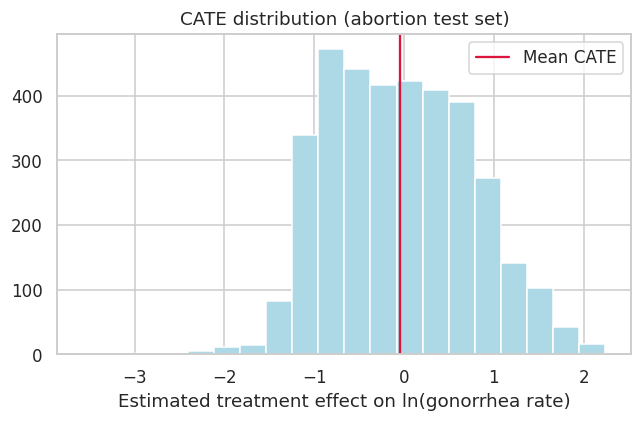

In [17]:
cate_test_pred = cf_model.predict(X_test)
print(
    f"CATE on test set: mean = {cate_test_pred.mean():.3f}, sd = {cate_test_pred.std():.3f}"
)
print("Range:", round(float(cate_test_pred.min()), 3), "to", round(float(cate_test_pred.max()), 3))
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(cate_test_pred, bins=20, color="lightblue", edgecolor="white")
ax.axvline(cate_test_pred.mean(), color="crimson", lw=1.5, label="Mean CATE")
ax.set_title("CATE distribution (abortion test set)")
ax.set_xlabel("Estimated treatment effect on ln(gonorrhea rate)")
ax.legend()
fig.tight_layout()
plt.show()


### Rank-Weighted Average Treatment Effect (RATE)

The **Rank-Weighted Average Treatment Effect (RATE)** and **Area Under the Prioritization Curve (AUTOC)** summarize treatment-effect heterogeneity. `rank_average_treatment_effect()` computes the targeting operator characteristic (TOC) after doubly robust scores are sorted by a priority score.

Below, a second forest is fit on half of the test sample. Priorities are the CATE predictions from the training forest. A rising TOC means that ranking units by the estimated CATE concentrates the treatment effect.


AUTOC: 1.321


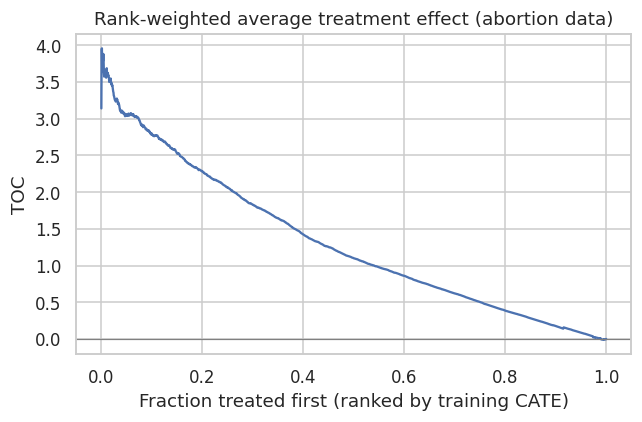

In [18]:
half = len(X_test) // 2
eval_forest = CausalForest(num_trees=60, min_node_size=5, random_state=11)
eval_forest.fit(X_test[half:], W_test[half:], Y_test[half:], feature_names=feature_names)
priorities = cf_model.predict(X_test[half:])
rate = eval_forest.rank_average_treatment_effect(priorities)
print("AUTOC:", round(rate["autoc"], 3))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rate["q"], rate["toc"], color="#4C72B0")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Fraction treated first (ranked by training CATE)")
ax.set_ylabel("TOC")
ax.set_title("Rank-weighted average treatment effect (abortion data)")
fig.tight_layout()
plt.show()


### Variable Importance


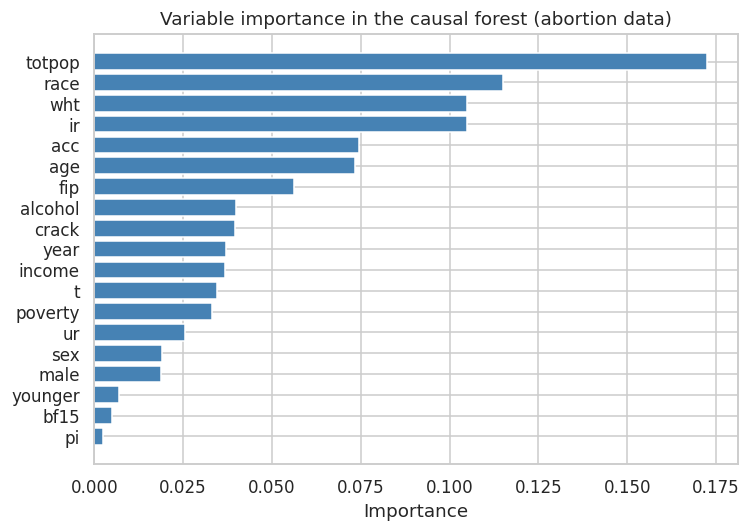

In [19]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": cf_model.feature_importance(),
}).sort_values("Importance")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance_df["Feature"], importance_df["Importance"], color="steelblue")
ax.set_title("Variable importance in the causal forest (abortion data)")
ax.set_xlabel("Importance")
fig.tight_layout()
plt.show()


### SHAP analysis

SHAP values for the forest's CATE predictions come from `explain()`. A subsample of the training data is used for speed. Importance, dependence, and waterfall plots use the explanation object returned by that method.


In [20]:
sv = cf_model.explain(X_train, max_samples=40, random_state=42, feature_names=feature_names)
print("SHAP matrix", sv.values.shape)


SHAP matrix (40, 19)


### Visualize SHAP values

Mean absolute SHAP value ranks covariates by how much they move the predicted CATE.


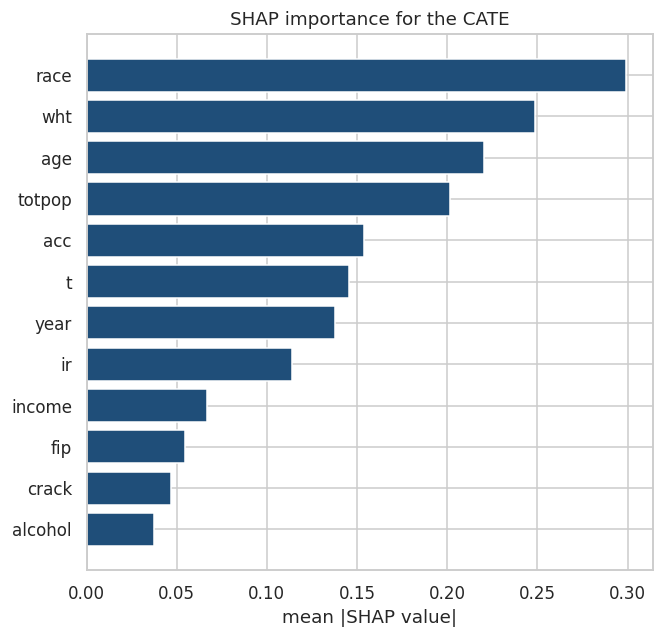

In [21]:
sv.plot_importance(max_display=12)
plt.show()


#### SHAP dependence

Dependence plots show how the SHAP value for a covariate changes as that covariate changes. The four plots below are the covariates with the largest forest importance.


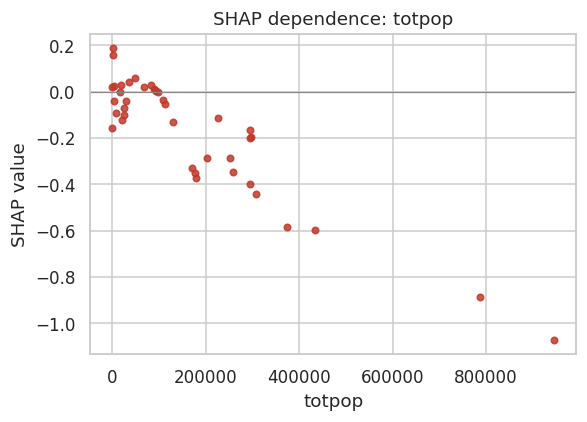

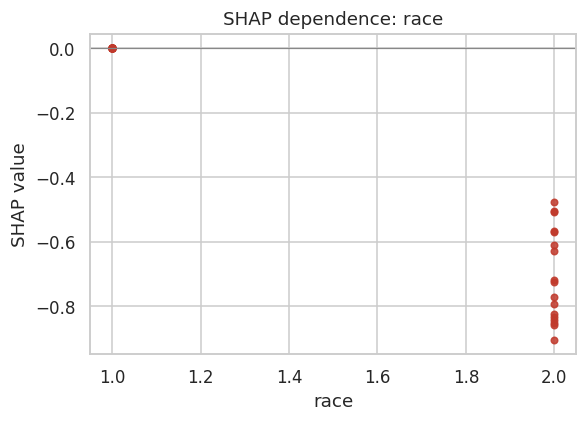

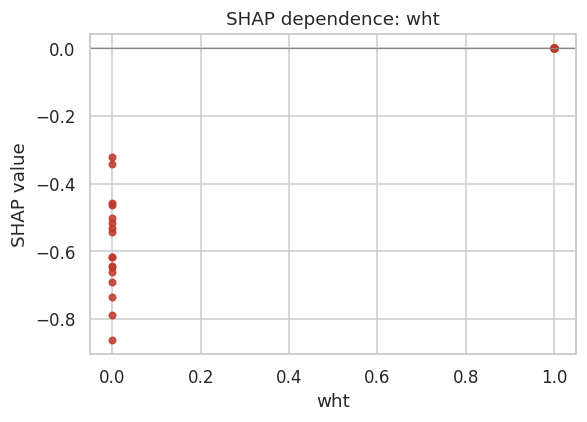

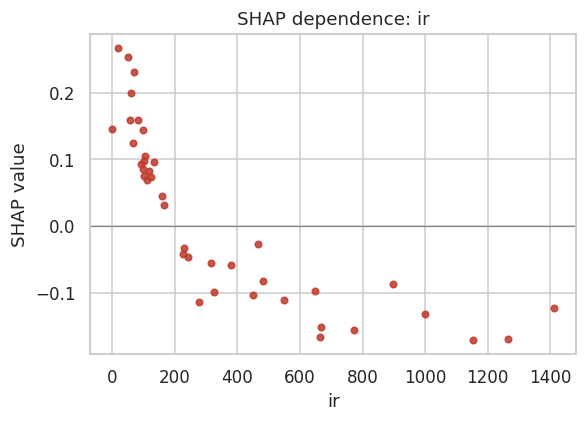

In [22]:
top_features = importance_df.sort_values("Importance", ascending=False)["Feature"].head(4)
for name in top_features:
    sv.plot_dependence(name)
    plt.show()


#### Decompose single predictions

A waterfall plot shows how each feature contributes to the predicted CATE for one observation.


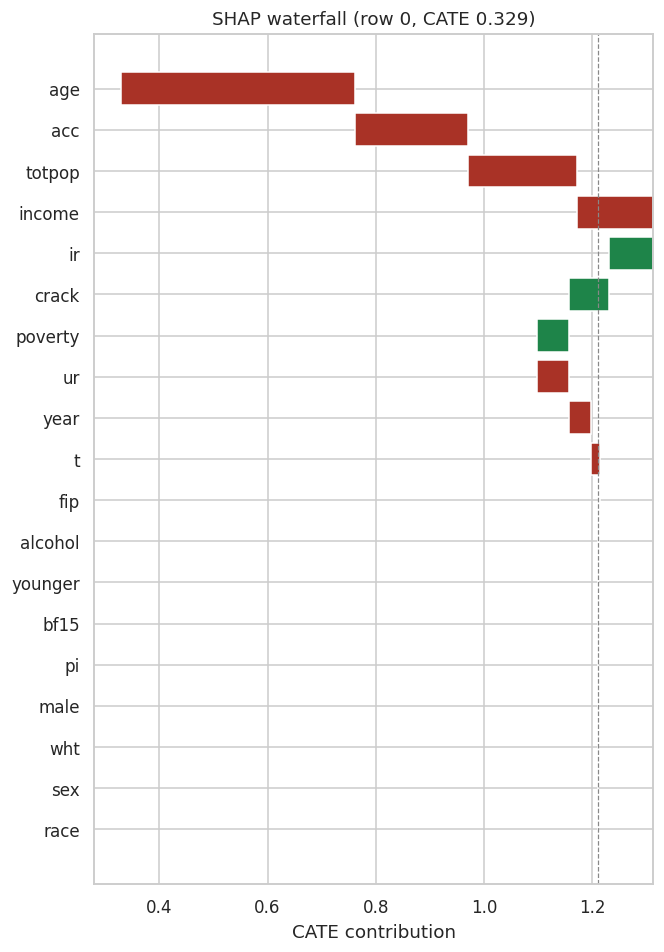

In [23]:
sv.plot_waterfall(row=0)
plt.show()


#### SHAP values for a female subgroup

`sex == 2` marks female state-year rows. The waterfall below is one explained female observation. The bar importance plot above still summarizes average absolute SHAP across the explained training rows.


Waterfall row (sex = 2): 30


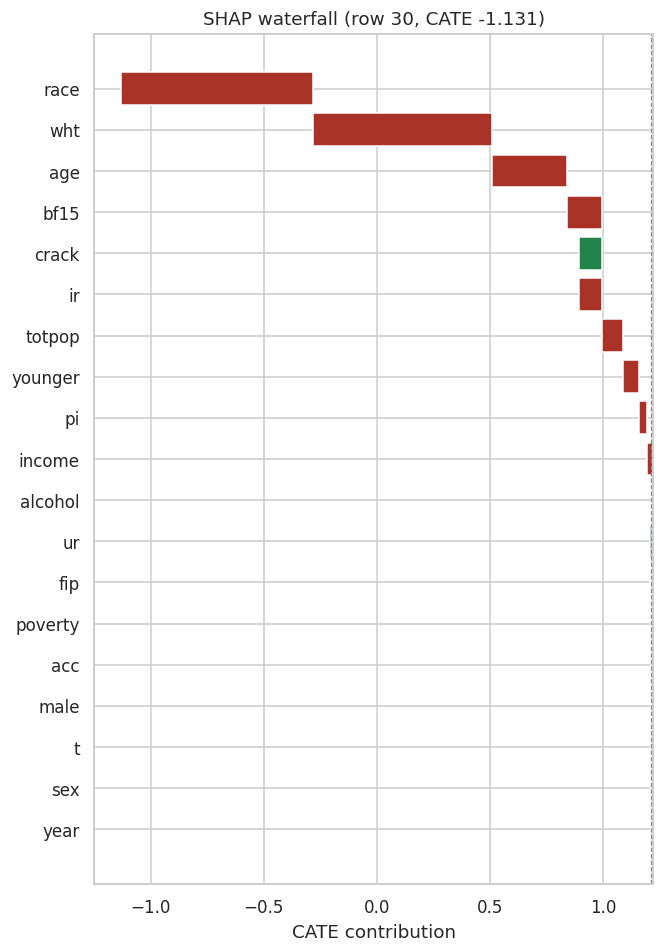

In [24]:
sex_col = feature_names.index("sex")
female_rows = np.flatnonzero(sv.data[:, sex_col] == 2)
if len(female_rows) == 0:
    row_show = int(np.argmax(np.abs(sv.values).sum(axis=1)))
    print("No female row in the SHAP subsample; showing the largest absolute prediction instead.")
else:
    row_show = int(female_rows[np.argmax(np.abs(sv.values[female_rows]).sum(axis=1))])
    print("Waterfall row (sex = 2):", row_show)
sv.plot_waterfall(row=row_show)
plt.show()


## Summary and Conclusion

Causal forests estimate heterogeneous treatment effects by averaging many trees grown to separate groups with different treatment effects. This tutorial used `CausalForest` from PyCausalML. It covered (1) **simulated data** from `synthetic_data()`, where the estimated CATE can be compared with the known effect, and (2) the **abortion** dataset, where early repeal is the treatment and the logged gonorrhea rate among 15–19 year olds is the outcome.

On the abortion data we prepared covariates, fit the forest, reported the training ATE with a confidence interval, predicted CATEs on a held-out sample, summarized prioritization with the rank-weighted average treatment effect, and interpreted the fit with variable importance and `explain()`. A single causal tree is easier to read leaf by leaf. A forest is the lower-variance estimate of the same conditional treatment effect, which is the right tool when the goal is a stable CATE rather than one interpretable partition.

## Resources

1. Athey, Susan, Julie Tibshirani, and Stefan Wager. "Generalized Random Forests". Annals of Statistics, 47(2), 2019.

2. Wager, Stefan, and Susan Athey. "Estimation and Inference of Heterogeneous Treatment Effects using Random Forests". Journal of the American Statistical Association, 113(523), 2018.

3. Nie, Xinkun, and Stefan Wager. "Quasi-Oracle Estimation of Heterogeneous Treatment Effects". Biometrika, 108(2), 2021.

4. The Effect (Huntington-Klein): https://theeffectbook.net
